# Task 7 - Sales Forecasting
**Elevvo ML Internship - Level 3**

Goal: forecast each Walmart store's sales for the next week from its historical sales, using time-based features (week, month, lag values, rolling averages) and regression models, then plot actual vs predicted sales over time.

Dataset: [Walmart Sales Forecast (Kaggle)](https://www.kaggle.com/datasets/aslanahmedov/walmart-sales-forecast) - put `train.csv`, `features.csv` and `stores.csv` in the same folder as this notebook (in Colab, upload them with the Files panel). In Colab, also run `!pip install rich` once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

In [2]:
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich import box

console = Console()
GREEN, CYAN, AMBER = '#33ff66', '#00e5ff', '#ffb000'
BORDER = '#15803d'  # darker green so borders stay visible on light backgrounds (e.g. GitHub)
PALETTE = [GREEN, CYAN, AMBER, '#ff4fd8', '#b388ff', '#ff6e6e', '#ffffff']

plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'monospace', 'axes.edgecolor': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': GREEN, 'ytick.color': GREEN, 'axes.titlecolor': GREEN,
    'axes.grid': True, 'grid.color': '#1f3d1f', 'grid.linestyle': ':',
})

def term_table(df, title, index=True):
    t = Table(title=f'> {title}', title_justify='left', title_style=f'bold {GREEN}',
              box=box.SQUARE, border_style=BORDER, header_style=f'bold {CYAN}')
    if index:
        t.add_column(str(df.index.name or ''), style=AMBER)
    for col in df.columns:
        t.add_column(str(col), justify='right', style=GREEN)
    for idx, *row in df.itertuples():
        values = [f'{v:,.3f}' if isinstance(v, float) else str(v) for v in row]
        t.add_row(*([str(idx)] if index else []), *values)
    console.print(t)

def term_panel(title, lines):
    body = '\n'.join(f'[{GREEN}]$[/] {line}' for line in lines)
    console.print(Panel(body, title=f'[bold {GREEN}]{title}', title_align='left',
                        border_style=BORDER, box=box.SQUARE, expand=False))

## 1. Load and merge the data
- `train.csv`: weekly sales per store **and department**
- `features.csv`: weekly temperature, fuel price, CPI, unemployment, markdowns and holiday flag per store
- `stores.csv`: store type (A/B/C) and size

We forecast sales per **store**, so department sales are summed for each store and week.

In [3]:
train = pd.read_csv('train.csv', parse_dates=['Date'])
features = pd.read_csv('features.csv', parse_dates=['Date'])
stores = pd.read_csv('stores.csv')

term_panel('RAW FILES', [f'train.csv    : {len(train):,} rows (store x department x week)',
                         f'features.csv : {len(features):,} rows', f'stores.csv   : {len(stores)} stores',
                         f'date range   : {train.Date.min().date()} -> {train.Date.max().date()}',
                         f'negative department sales (returns) : {(train.Weekly_Sales < 0).sum():,}'])

┌─ RAW FILES ───────────────────────────────────────────────┐
│ $ train.csv    : 421,570 rows (store x department x week) │
│ $ features.csv : 8,190 rows                               │
│ $ stores.csv   : 45 stores                                │
│ $ date range   : 2010-02-05 -> 2012-10-26                 │
│ $ negative department sales (returns) : 1,285             │
└───────────────────────────────────────────────────────────┘

In [4]:
sales = train.groupby(['Store', 'Date'], as_index=False)['Weekly_Sales'].sum()
df = (sales.merge(features, on=['Store', 'Date'], how='left')
            .merge(stores, on='Store', how='left')
            .sort_values(['Store', 'Date'])
            .reset_index(drop=True))

missing = df.isnull().sum()
term_table(missing[missing > 0].to_frame('missing').assign(share=lambda m: m['missing'] / len(df)), 'MISSING VALUES AFTER MERGE')

> MISSING VALUES AFTER MERGE   
┌───────────┬─────────┬───────┐
│           │ missing │ share │
├───────────┼─────────┼───────┤
│ MarkDown1 │    4155 │ 0.646 │
│ MarkDown2 │    4798 │ 0.746 │
│ MarkDown3 │    4389 │ 0.682 │
│ MarkDown4 │    4470 │ 0.695 │
│ MarkDown5 │    4140 │ 0.643 │
└───────────┴─────────┴───────┘

## 2. Cleaning
The five MarkDown columns (promotions) are mostly empty and only recorded from November 2011, so they are dropped. Nothing else is missing in the training period.

In [5]:
df = df.drop(columns=[f'MarkDown{i}' for i in range(1, 6)])
df['IsHoliday'] = df['IsHoliday'].astype(int)
df['Type'] = df['Type'].map({'A': 0, 'B': 1, 'C': 2})
term_panel('CLEAN STORE-WEEK TABLE', [f'rows    : {len(df):,} ({df.Store.nunique()} stores x {df.Date.nunique()} weeks)',
                                     f'missing : {df.isnull().sum().sum()}'])
term_table(df.head(3).T.rename(columns=lambda i: f'row {i}'), 'FIRST 3 ROWS')

┌─ CLEAN STORE-WEEK TABLE ──────────────────┐
│ $ rows    : 6,435 (45 stores x 143 weeks) │
│ $ missing : 0                             │
└───────────────────────────────────────────┘

> FIRST 3 ROWS                                                                    
┌──────────────┬─────────────────────┬─────────────────────┬─────────────────────┐
│              │               row 0 │               row 1 │               row 2 │
├──────────────┼─────────────────────┼─────────────────────┼─────────────────────┤
│ Store        │                   1 │                   1 │                   1 │
│ Date         │ 2010-02-05 00:00:00 │ 2010-02-12 00:00:00 │ 2010-02-19 00:00:00 │
│ Weekly_Sales │       1,643,690.900 │       1,641,957.440 │       1,611,968.170 │
│ Temperature  │              42.310 │              38.510 │              39.930 │
│ Fuel_Price   │               2.572 │               2.548 │               2.514 │
│ CPI          │             211.096 │             211.242 │             211.289 │
│ Unemployment │               8.106 │               8.106 │               8.106 │
│ IsHoliday    │                   0 │                   1 │                   0 │
│ Type         │                   0 │                   0 │                   0 │
│ Size         │              151315 │              151315 │              151315 │
└──────────────┴─────────────────────┴─────────────────────┴─────────────────────┘

## 3. Sales over time

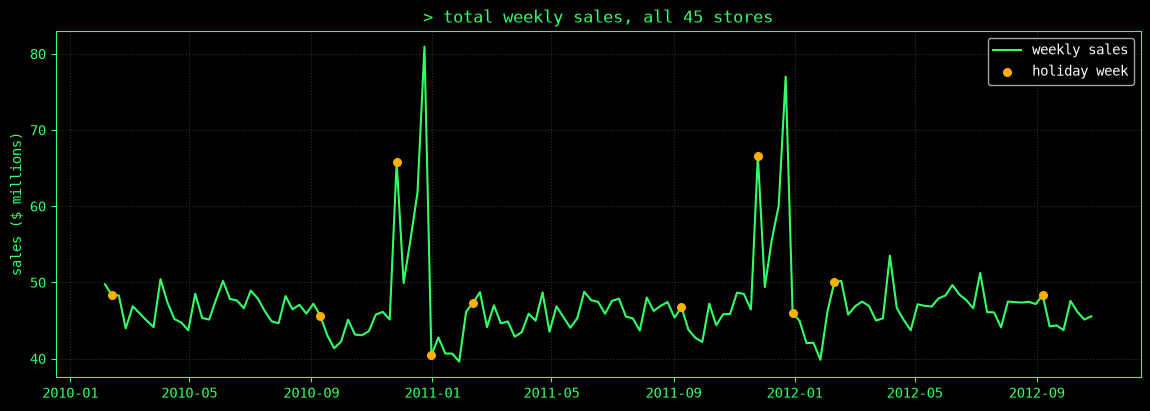

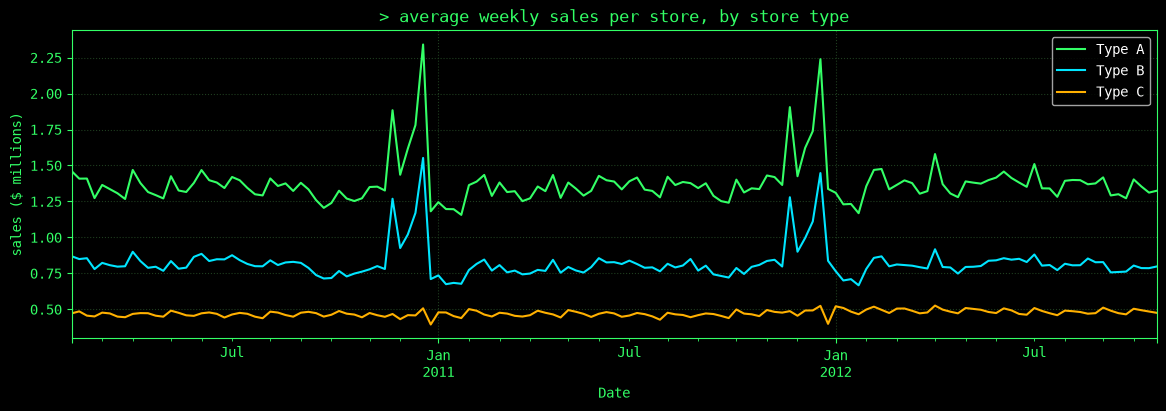

In [6]:
total = df.groupby('Date')['Weekly_Sales'].sum() / 1e6
holidays = df.loc[df.IsHoliday == 1, 'Date'].unique()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(total.index, total, color=GREEN, linewidth=1.5, label='weekly sales')
ax.scatter(holidays, total.loc[holidays], color=AMBER, zorder=3, s=30, label='holiday week')
ax.set(title='> total weekly sales, all 45 stores', ylabel='sales ($ millions)')
ax.legend()
plt.show()

by_type = df.groupby(['Date', 'Type'])['Weekly_Sales'].mean().unstack() / 1e6
by_type.columns = ['Type A', 'Type B', 'Type C']
by_type.plot(figsize=(14, 4), color=[GREEN, CYAN, AMBER], title='> average weekly sales per store, by store type')
plt.ylabel('sales ($ millions)')
plt.show()

## 4. Bonus: rolling averages and seasonal decomposition

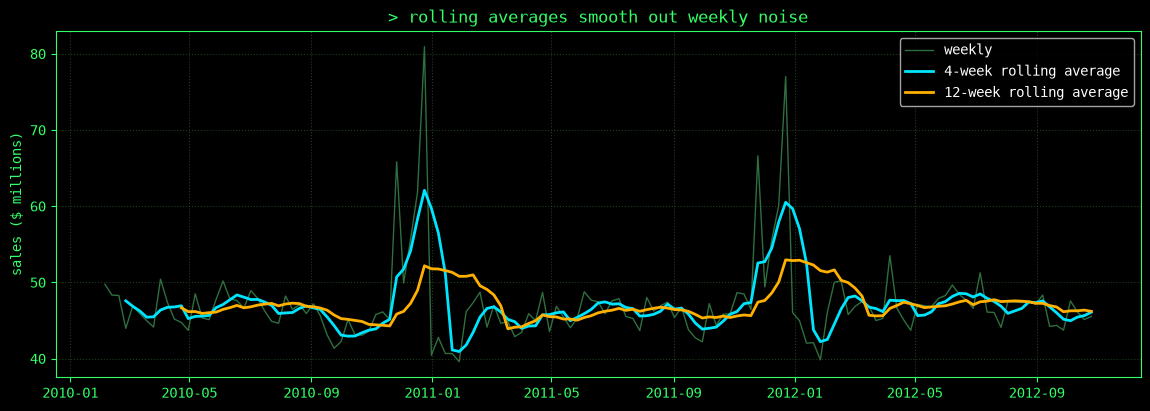

In [7]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(total.index, total, color='#2f6f3f', linewidth=1, label='weekly')
ax.plot(total.index, total.rolling(4).mean(), color=CYAN, linewidth=2, label='4-week rolling average')
ax.plot(total.index, total.rolling(12).mean(), color=AMBER, linewidth=2, label='12-week rolling average')
ax.set(title='> rolling averages smooth out weekly noise', ylabel='sales ($ millions)')
ax.legend()
plt.show()

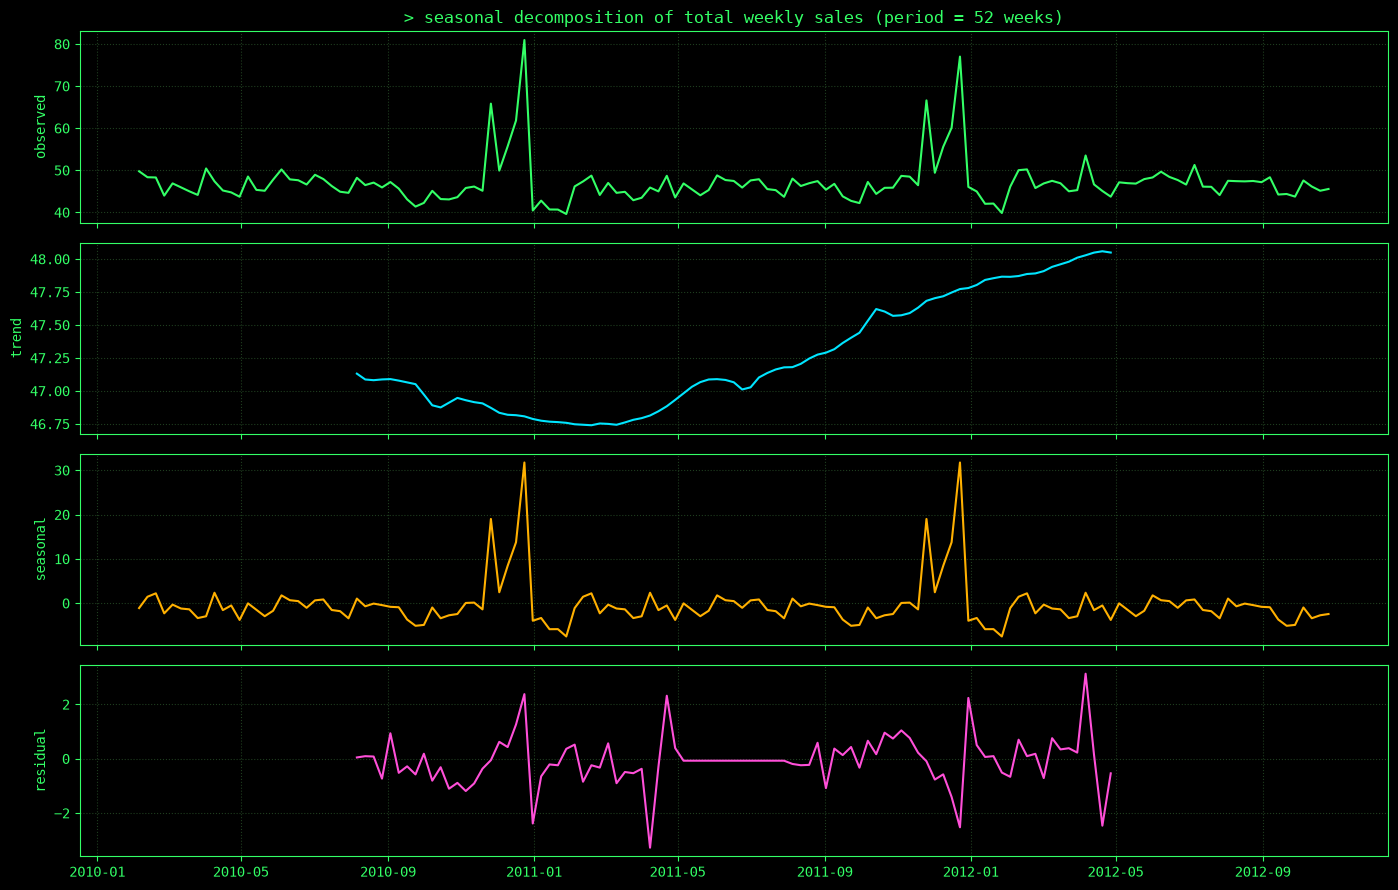

┌─ SEASONALITY ───────────────────────────────────────────────────┐
│ $ trend change over the period : +0.92 M per week               │
│ $ strongest seasonal week      : 2010-12-24 (+31.8 M vs normal) │
│ $ weakest seasonal week        : 2011-01-28 (-7.5 M vs normal)  │
└─────────────────────────────────────────────────────────────────┘

In [8]:
decomp = seasonal_decompose(total, model='additive', period=52)
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, (name, series), color in zip(axes, [('observed', decomp.observed), ('trend', decomp.trend),
                                            ('seasonal', decomp.seasonal), ('residual', decomp.resid)],
                                     [GREEN, CYAN, AMBER, '#ff4fd8']):
    ax.plot(series.index, series, color=color)
    ax.set_ylabel(name)
axes[0].set_title('> seasonal decomposition of total weekly sales (period = 52 weeks)')
plt.tight_layout()
plt.show()

season = decomp.seasonal
term_panel('SEASONALITY', [f'trend change over the period : {decomp.trend.dropna().iloc[-1] - decomp.trend.dropna().iloc[0]:+.2f} M per week',
                           f'strongest seasonal week      : {season.idxmax().date()} ({season.max():+.1f} M vs normal)',
                           f'weakest seasonal week        : {season.idxmin().date()} ({season.min():+.1f} M vs normal)'])

## 5. Time-based features
For each store we create:
- **calendar features:** week of year, month, year, holiday flag
- **lag features:** sales 1 and 2 weeks ago, and the **same week last year** (lag 52, which captures holiday peaks)
- **rolling average:** mean of the previous 4 weeks

Lags only use past weeks, so the model never sees the week it is predicting. The first 52 weeks of each store are dropped because they have no last-year value.

In [9]:
df['week'] = df['Date'].dt.isocalendar().week.astype(int)
df['month'] = df['Date'].dt.month
df['year'] = df['Date'].dt.year

by_store = df.groupby('Store')['Weekly_Sales']
for lag in [1, 2, 52]:
    df[f'lag_{lag}'] = by_store.shift(lag)
df['rolling_mean_4'] = by_store.transform(lambda s: s.shift(1).rolling(4).mean())

model_df = df.dropna().reset_index(drop=True)
FEATURES = ['Store', 'Type', 'Size', 'IsHoliday', 'week', 'month', 'year', 'Temperature', 'Fuel_Price', 'CPI',
            'Unemployment', 'lag_1', 'lag_2', 'lag_52', 'rolling_mean_4']
term_panel('FEATURE TABLE', [f'rows     : {len(model_df):,}', f'features : {len(FEATURES)}',
                             f'from     : {model_df.Date.min().date()}'])

┌─ FEATURE TABLE ─────────┐
│ $ rows     : 4,095      │
│ $ features : 15         │
│ $ from     : 2011-02-04 │
└─────────────────────────┘

## 6. Time-based train / test split
With time series you can't shuffle: the model must be trained on the past and tested on the future. The **last 20 weeks** are the test period.

In [10]:
cutoff = model_df['Date'].max() - pd.Timedelta(weeks=20)
train_df, test_df = model_df[model_df.Date <= cutoff], model_df[model_df.Date > cutoff]
X_train, y_train = train_df[FEATURES], train_df['Weekly_Sales']
X_test, y_test = test_df[FEATURES], test_df['Weekly_Sales']
term_panel('TRAIN / TEST SPLIT (BY TIME)', [f'train : {train_df.Date.min().date()} -> {train_df.Date.max().date()} ({len(train_df):,} rows)',
                                           f'test  : {test_df.Date.min().date()} -> {test_df.Date.max().date()} ({len(test_df):,} rows)'])

┌─ TRAIN / TEST SPLIT (BY TIME) ──────────────────┐
│ $ train : 2011-02-04 -> 2012-06-08 (3,195 rows) │
│ $ test  : 2012-06-15 -> 2012-10-26 (900 rows)   │
└─────────────────────────────────────────────────┘

## 7. Train and evaluate models
Two simple baselines are included to check the models actually add value:
- **Naive (last week):** predict the same sales as last week
- **Naive (last year):** predict the same sales as the same week last year

Metrics: MAE and RMSE in dollars, and **WMAPE** (total absolute error as a share of total sales).

In [11]:
def evaluate(y_true, y_pred):
    return {'MAE ($)': mean_absolute_error(y_true, y_pred),
            'RMSE ($)': np.sqrt(mean_squared_error(y_true, y_pred)),
            'WMAPE': np.abs(y_true - y_pred).sum() / y_true.sum()}

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8,
                            colsample_bytree=0.8, n_jobs=-1, random_state=42),
}

results = {'Naive (last week)': evaluate(y_test, test_df['lag_1']),
           'Naive (last year)': evaluate(y_test, test_df['lag_52'])}
predictions = {}
for name, model in models.items():
    predictions[name] = model.fit(X_train, y_train).predict(X_test)
    results[name] = evaluate(y_test, predictions[name])

results_df = pd.DataFrame(results).T.sort_values('MAE ($)')
best_name = results_df.drop(index=['Naive (last week)', 'Naive (last year)']).index[0]
term_table(results_df, 'FORECAST ACCURACY (LAST 20 WEEKS)')

> FORECAST ACCURACY (LAST 20 WEEKS)                    
┌───────────────────┬────────────┬────────────┬───────┐
│                   │    MAE ($) │   RMSE ($) │ WMAPE │
├───────────────────┼────────────┼────────────┼───────┤
│ Random Forest     │ 40,241.493 │ 65,044.683 │ 0.039 │
│ Linear Regression │ 40,984.795 │ 65,258.231 │ 0.040 │
│ XGBoost           │ 43,201.557 │ 67,621.616 │ 0.042 │
│ Naive (last week) │ 51,838.362 │ 79,029.195 │ 0.050 │
│ Naive (last year) │ 53,465.428 │ 84,106.064 │ 0.052 │
└───────────────────┴────────────┴────────────┴───────┘

## 8. Bonus: time-aware cross-validation
`TimeSeriesSplit` trains on an expanding window of past weeks and validates on the weeks right after it, five times, so every validation fold is in the future of its training data.

In [12]:
tscv = TimeSeriesSplit(n_splits=5)
dates = np.sort(train_df['Date'].unique())
cv_rows = []
for fold, (tr_d, va_d) in enumerate(tscv.split(dates), start=1):
    tr = train_df[train_df.Date.isin(dates[tr_d])]
    va = train_df[train_df.Date.isin(dates[va_d])]
    row = {'validation weeks': f'{pd.Timestamp(dates[va_d][0]).date()} -> {pd.Timestamp(dates[va_d][-1]).date()}'}
    for name in ['Random Forest', 'XGBoost']:
        m = clone(models[name]).fit(tr[FEATURES], tr['Weekly_Sales'])  # fresh copy, so the final models stay untouched
        row[f'{name} WMAPE'] = evaluate(va['Weekly_Sales'], m.predict(va[FEATURES]))['WMAPE']
    cv_rows.append(row)

cv = pd.DataFrame(cv_rows, index=pd.Index(range(1, 6), name='fold'))
term_table(cv, 'TIME SERIES CROSS-VALIDATION')
term_panel('AVERAGE CV WMAPE', [f'Random Forest : {cv["Random Forest WMAPE"].mean():.3%}',
                                f'XGBoost       : {cv["XGBoost WMAPE"].mean():.3%}'])

> TIME SERIES CROSS-VALIDATION                                           
┌──────┬──────────────────────────┬─────────────────────┬───────────────┐
│ fold │         validation weeks │ Random Forest WMAPE │ XGBoost WMAPE │
├──────┼──────────────────────────┼─────────────────────┼───────────────┤
│ 1    │ 2011-05-27 -> 2011-08-05 │               0.036 │         0.039 │
│ 2    │ 2011-08-12 -> 2011-10-21 │               0.041 │         0.043 │
│ 3    │ 2011-10-28 -> 2012-01-06 │               0.107 │         0.102 │
│ 4    │ 2012-01-13 -> 2012-03-23 │               0.043 │         0.046 │
│ 5    │ 2012-03-30 -> 2012-06-08 │               0.048 │         0.054 │
└──────┴──────────────────────────┴─────────────────────┴───────────────┘

┌─ AVERAGE CV WMAPE ───────┐
│ $ Random Forest : 5.482% │
│ $ XGBoost       : 5.698% │
└──────────────────────────┘

## 9. Actual vs predicted over time

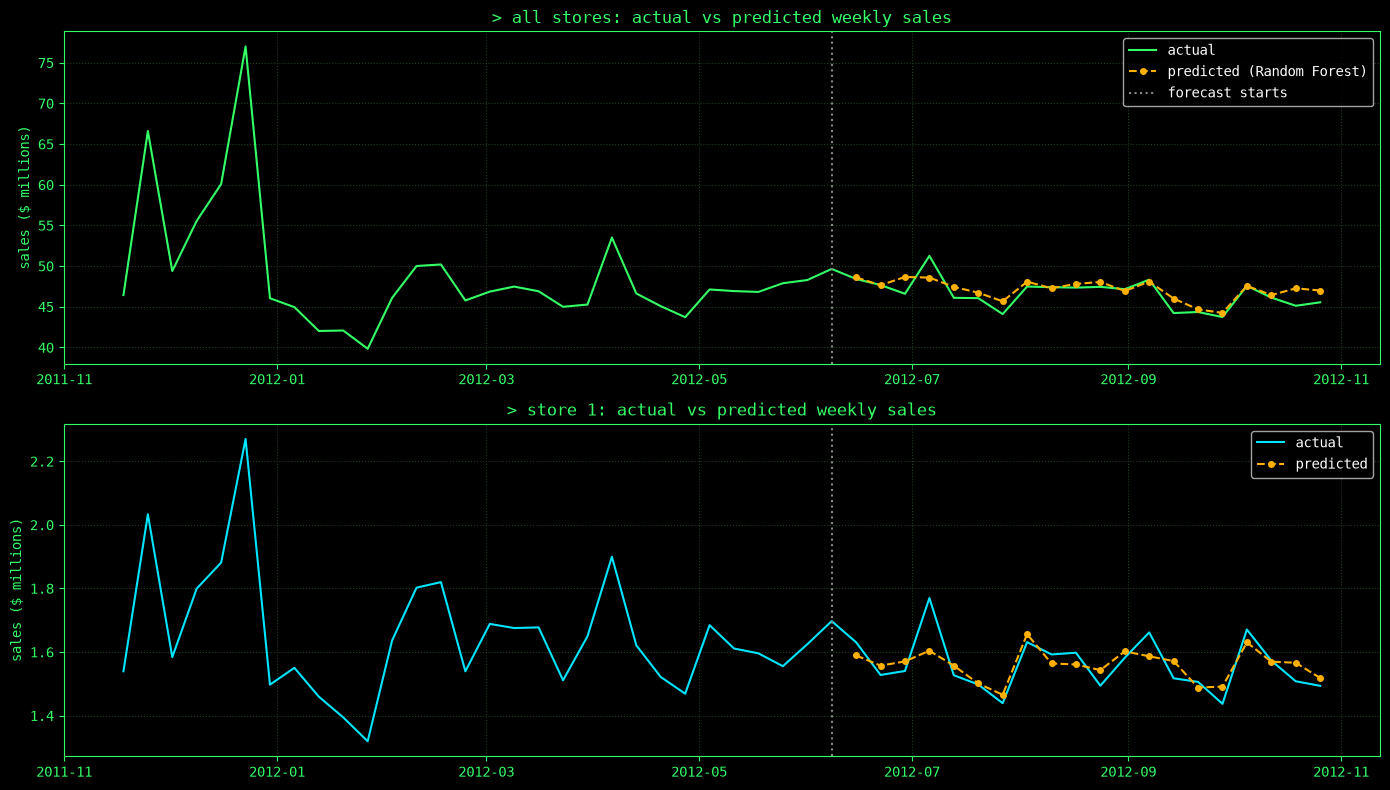

In [13]:
plot_df = test_df[['Date', 'Store', 'Weekly_Sales']].assign(pred=predictions[best_name])
history = df[df.Date > cutoff - pd.Timedelta(weeks=30)]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
hist_total = history.groupby('Date')['Weekly_Sales'].sum() / 1e6
pred_total = plot_df.groupby('Date')[['Weekly_Sales', 'pred']].sum() / 1e6
axes[0].plot(hist_total.index, hist_total, color=GREEN, label='actual')
axes[0].plot(pred_total.index, pred_total['pred'], color=AMBER, linestyle='--', marker='o', markersize=4, label=f'predicted ({best_name})')
axes[0].axvline(cutoff, color='#888888', linestyle=':', label='forecast starts')
axes[0].set(title='> all stores: actual vs predicted weekly sales', ylabel='sales ($ millions)')
axes[0].legend()

store = 1
hist_store = history[history.Store == store].set_index('Date')['Weekly_Sales'] / 1e6
pred_store = plot_df[plot_df.Store == store].set_index('Date')['pred'] / 1e6
axes[1].plot(hist_store.index, hist_store, color=CYAN, label='actual')
axes[1].plot(pred_store.index, pred_store, color=AMBER, linestyle='--', marker='o', markersize=4, label='predicted')
axes[1].axvline(cutoff, color='#888888', linestyle=':')
axes[1].set(title=f'> store {store}: actual vs predicted weekly sales', ylabel='sales ($ millions)')
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. What drives the forecast?

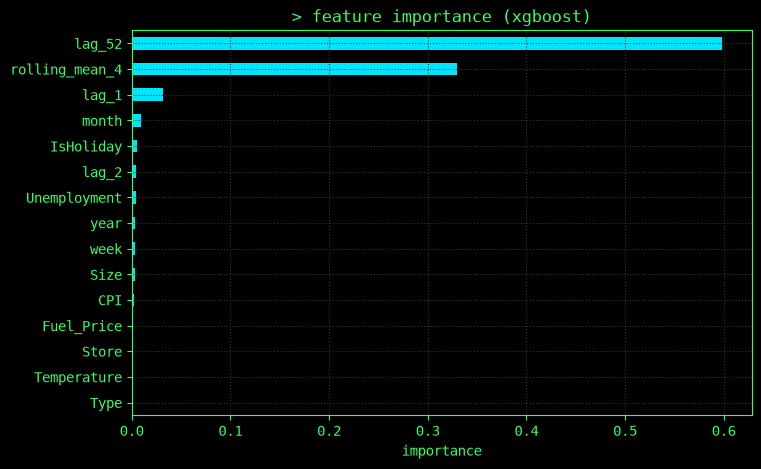

> TOP 6 FEATURES               
┌────────────────┬────────────┐
│                │ importance │
├────────────────┼────────────┤
│ lag_52         │      0.598 │
│ rolling_mean_4 │      0.330 │
│ lag_1          │      0.031 │
│ month          │      0.009 │
│ IsHoliday      │      0.005 │
│ lag_2          │      0.005 │
└────────────────┴────────────┘

In [14]:
importance = pd.Series(models['XGBoost'].feature_importances_, index=FEATURES).sort_values(ascending=False)
importance.sort_values().plot(kind='barh', figsize=(8, 5), color=CYAN, title='> feature importance (xgboost)')
plt.xlabel('importance')
plt.show()
term_table(importance.head(6).to_frame('importance'), 'TOP 6 FEATURES')

## 11. Conclusions

- **Data:** 421,570 store-department-week rows were summed into **6,435 store-week rows** (45 stores x 143 weeks, Feb 2010 to Oct 2012). The five MarkDown columns were 64-75% empty and were dropped; nothing else was missing.
- **Seasonality (bonus):** the decomposition shows a strong yearly pattern. Christmas week adds about **$31.8M** above a normal week for all stores combined, and late January is the weakest period. The underlying trend rose by about $0.9M per week over the period.
- **Time features:** week, month, year, holiday flag, lags of 1, 2 and 52 weeks, and a 4-week rolling average. The model was trained on Feb 2011 to Jun 2012 and tested on the **last 20 weeks** (Jun to Oct 2012).
- **Results:** Random Forest forecasts next week's store sales with **3.9% WMAPE** (MAE about $40k on stores selling about $1M per week), beating the naive baselines of repeating last week (5.0%) or last year (5.2%). Linear regression is almost as good (4.0%), and XGBoost scored 4.2%.
- **Time-aware validation (bonus):** across 5 expanding time-series folds, Random Forest averages 5.5% WMAPE and XGBoost 5.7%. The fold covering the holiday season (Nov 2011 to Jan 2012) is much harder (about 10%).
- **What drives the forecast:** sales in the same week last year (lag 52) and the recent 4-week average explain over 90% of the XGBoost model. Temperature, fuel price, CPI and unemployment add very little.